# Math 32 — Lecture 27: Confidence Intervals

Companion notebook for Lecture 27. Every figure and number in the slides is made here.

**How this notebook is organized.** Every code cell is **self-contained**, so you can change a number
(the confidence level, $n$, $\sigma$, the seed, ...) and re-run just that cell.
Figures are saved in a `figures/` folder next to the notebook.

**Critical values** from Table B.1 ($P(Z \ge z_{\alpha/2}) = \alpha/2$): $90\% \to 1.645$, $\ 95\% \to 1.96$, $\ 99\% \to 2.575$.

## 1. What does "95% confidence" mean?

Pretend we **know** the true mean $\mu = 300$. We collect 50 separate data sets ($n = 64$ days each, $\sigma = 32$)
and build a 95% confidence interval $\bar x \pm 1.96\,\sigma/\sqrt n$ from each one.
About 95% of the intervals should contain $\mu$ — the **method** works 95% of the time.

**Try it:** change `z` to `1.645` (90%) or `2.575` (99%). How many intervals miss now?

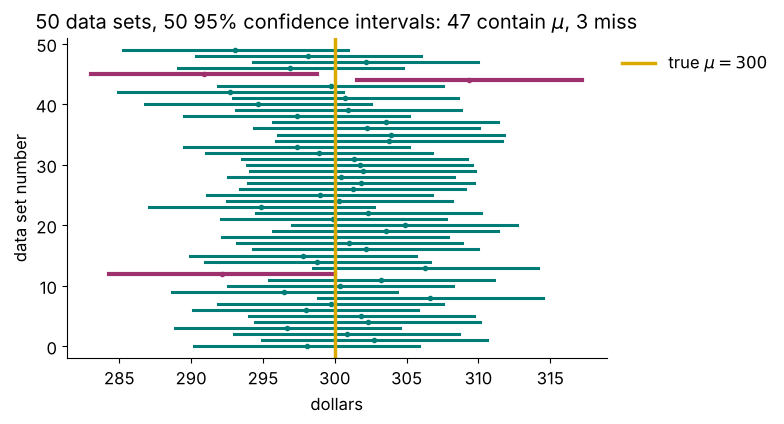

47 of 50 intervals contain the true mean
fraction of 100,000 intervals containing mu: 0.95013


In [1]:
# What does "95% confidence" mean?  Make 50 confidence intervals from 100 fresh data sets.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from math import sqrt

NAVY, GOLD, TEAL, MAGENTA, GRAY = "#0F2D52", "#DBAA01", "#007C77", "#9D316E", "#7A7A7A"
OUTDIR = Path("figures"); OUTDIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

rng = np.random.default_rng(9)
mu, sigma, n, z = 300, 32, 64, 1.96          # true mean (unknown in real life!), known sigma, sample size, z_{0.025}
reps = 50
xbar = rng.normal(mu, sigma, size=(reps, n)).mean(axis=1)
half = z * sigma / sqrt(n)
lo, hi = xbar - half, xbar + half
hit = (lo < mu) & (mu < hi)

fig, ax = plt.subplots(figsize=(8, 4.4))
for i in range(reps):
    ax.plot([lo[i], hi[i]], [i, i], color=TEAL if hit[i] else MAGENTA, lw=2.2 if hit[i] else 3)
    ax.plot(xbar[i], i, "o", ms=3, color=TEAL if hit[i] else MAGENTA)
ax.axvline(mu, color=GOLD, lw=2.5, label=r"true $\mu = 300$")
ax.set(xlabel="dollars", ylabel="data set number", ylim=(-2, reps + 1),
       title=f"50 data sets, 50 95% confidence intervals: {hit.sum()} contain $\\mu$, {reps - hit.sum()} miss")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
fig.savefig(OUTDIR / "ci_50_intervals.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()
print(f"{hit.sum()} of {reps} intervals contain the true mean")

# with many more data sets, the fraction that contain mu is very close to 0.95
xbar = rng.normal(mu, sigma, size=(100_000, n)).mean(axis=1)
print("fraction of 100,000 intervals containing mu:", np.mean(np.abs(xbar - mu) < half))

## 2. The coffee cart: confidence intervals for a mean

The owner records $n = 64$ days with $\bar x = \$310$ and $\sigma = \$32$, so the standard error is $\sigma/\sqrt n = 4$ and
$$\bar x \ \pm\ z_{\alpha/2}\,\frac{\sigma}{\sqrt n}.$$
More confidence means a bigger $z_{\alpha/2}$ — and a wider interval.

In [2]:
# Example 1: confidence intervals for the mean daily sales (n = 64 days, xbar = 310, sigma = 32)
from math import sqrt
xbar, sigma, n = 310, 32, 64
se = sigma / sqrt(n)
print("standard error:", se)
for level, z in [(0.90, 1.645), (0.95, 1.96), (0.99, 2.575)]:
    m = z * se
    print(f"{int(level*100)}%: z = {z}, margin = {m:.2f}, interval = [{xbar - m:.2f}, {xbar + m:.2f}], width = {2*m:.2f}")

standard error: 4.0
90%: z = 1.645, margin = 6.58, interval = [303.42, 316.58], width = 13.16
95%: z = 1.96, margin = 7.84, interval = [302.16, 317.84], width = 15.68
99%: z = 2.575, margin = 10.30, interval = [299.70, 320.30], width = 20.60


## 3. An election poll: a confidence interval for a proportion

520 of 1000 voters support candidate G. Plug in $\hat p$ for the unknown $p$:
$$\hat p \ \pm\ z_{\alpha/2}\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$
The last lines check by simulation that intervals built this way contain the true $p$ about 95% of the time.

**Try it:** the "Your Turn" poll from the slides — $n = 400$, $\hat p = 0.46$, 90% level ($z = 1.645$).

In [3]:
# Example 2: a confidence interval for a proportion (520 of 1000 voters support G)
import numpy as np
from math import sqrt
n, x = 1000, 520
phat = x / n
se = sqrt(phat * (1 - phat) / n)
m = 1.96 * se
print(f"phat = {phat}, standard error = {se:.4f}, margin = {m:.4f}, 95% CI = [{phat - m:.4f}, {phat + m:.4f}]")

# check: if the true p were 0.5, how often would a 95% interval built this way contain p?
rng = np.random.default_rng(16)
ph = rng.binomial(n, 0.5, size=100_000) / n
m_sim = 1.96 * np.sqrt(ph * (1 - ph) / n)
print("coverage when p = 0.5:", np.mean(np.abs(ph - 0.5) < m_sim))

phat = 0.52, standard error = 0.0158, margin = 0.0310, 95% CI = [0.4890, 0.5510]
coverage when p = 0.5: 0.9455


## 4. How many days of data? Choosing the sample size

To get a margin of error of at most $m$:
$$n \ \ge\ \left(\frac{z_{\alpha/2}\,\sigma}{m}\right)^2 \qquad \text{(always round up!)}$$

**Try it:** what if the owner only needs $\pm\$10$? What about $\pm\$2.50$?

In [4]:
# Example 3: how many days of data to know the mean within +/- $5?
import math
sigma, m = 32, 5
for level, z in [(0.95, 1.96), (0.99, 2.575)]:
    n_exact = (z * sigma / m) ** 2
    print(f"{int(level*100)}%: n >= ({z}*{sigma}/{m})^2 = {n_exact:.2f}  -> {math.ceil(n_exact)} days")

95%: n >= (1.96*32/5)^2 = 157.35  -> 158 days
99%: n >= (2.575*32/5)^2 = 271.59  -> 272 days
